# Plot GEN files
Plot one or more GEN files side by side, e.g. to compare GENPUZZLE input and output.

In [4]:
from pathlib import Path

import imod
import matplotlib.pyplot as plt

from convert import init_logging
from genpuzzle import genpuzzle

init_logging()

imod: 2026-10-19 15:00:44,770 | INFO | convert.py:240 | 28400 >>> Logging initialized.


In [5]:
data_dir = Path("tests/data")
genfile_in = data_dir / "genpuzzle_test.gen"
tolerances = [0.0, 5.0]

genfiles = [genfile_in]
for tolerance in tolerances:
    genfile_out = data_dir / f"out_tol{tolerance:g}.gen"
    genpuzzle(genfile_in, genfile_out, tolerance)
    genfiles.append(genfile_out)

imod: 2026-10-19 15:00:44,783 | INFO | genpuzzle.py:17 | 28400 >>> Reading GEN file: tests\data\genpuzzle_test.gen
imod: 2026-10-19 15:00:44,795 | INFO | genpuzzle.py:29 | 28400 >>> Snapping 8 lines with tolerance: 0.0
imod: 2026-10-19 15:00:44,798 | INFO | genpuzzle.py:47 | 28400 >>> Merging snapped lines into continuous segments
imod: 2026-10-19 15:00:44,799 | INFO | genpuzzle.py:50 | 28400 >>> Merged 8 lines into 5 segments
imod: 2026-10-19 15:00:44,802 | INFO | genpuzzle.py:71 | 28400 >>> Writing GEN file: tests\data\out_tol0.gen
imod: 2026-10-19 15:00:44,811 | INFO | genpuzzle.py:17 | 28400 >>> Reading GEN file: tests\data\genpuzzle_test.gen
imod: 2026-10-19 15:00:44,820 | INFO | genpuzzle.py:29 | 28400 >>> Snapping 8 lines with tolerance: 5.0
imod: 2026-10-19 15:00:44,821 | INFO | genpuzzle.py:47 | 28400 >>> Merging snapped lines into continuous segments
imod: 2026-10-19 15:00:44,822 | INFO | genpuzzle.py:50 | 28400 >>> Merged 8 lines into 4 segments
imod: 2026-10-19 15:00:44,825

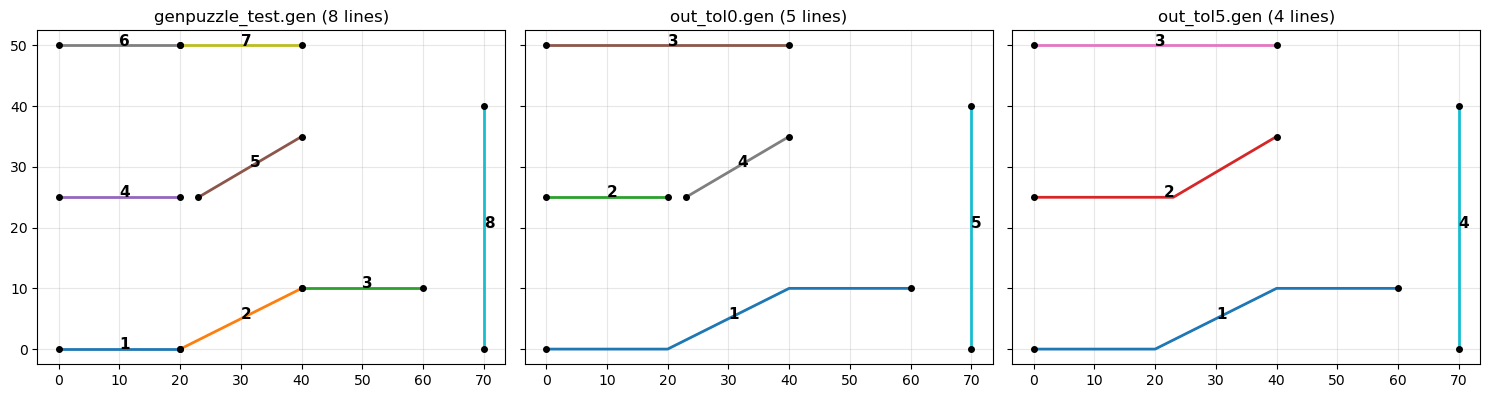

In [6]:
fig, axes = plt.subplots(
    1, len(genfiles), figsize=(5 * len(genfiles), 5), sharex=True, sharey=True, squeeze=False
)
for ax, genfile in zip(axes[0], genfiles):
    gdf = imod.formats.gen.read(genfile)
    gdf.plot(ax=ax, column="id", cmap="tab10", linewidth=2)
    for line_id, line in zip(gdf["id"], gdf.geometry):
        (x0, y0), (x1, y1) = line.coords[0], line.coords[-1]
        ax.plot([x0, x1], [y0, y1], "ko", markersize=4)
        mid = line.interpolate(0.5, normalized=True)
        ax.annotate(str(line_id), (mid.x, mid.y), fontsize=11, weight="bold")
    ax.set_title(f"{genfile.name} ({len(gdf)} lines)")
    ax.set_aspect("equal")
    ax.grid(alpha=0.3)
fig.tight_layout()